# 05 · Quem ganha abaixo do próprio perfil está saindo?

"Ganhar pouco" depende de com quem se compara. Aqui a comparação é com o
**próprio perfil**: o salário que o modelo do caderno 04 espera para alguém
com o mesmo cargo, nível, experiência, estado, escolaridade, gênero, porte de
empresa, vínculo, modelo de trabalho e ano.

Como só a faixa é conhecida, a distância de cada pessoa ao próprio perfil é
o **resíduo generalizado**: o desvio esperado, dado que o salário está
dentro da faixa declarada (`RegressaoIntervalar.residuo_generalizado`,
testado em dados simulados: correlação acima de 0,85 com o desvio
verdadeiro).

Três perguntas da pesquisa entram como resultado: se a pessoa está
satisfeita na empresa, se pretende mudar de emprego nos próximos 6 meses e,
para quem está insatisfeita, se o salário é um dos motivos.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from salarios.estatistica import RegressaoIntervalar, sem_categorias_vazias
from salarios.graficos import AZUL, LARANJA, TINTA_2, estilo
from salarios.ipca import fator

estilo()
df = pd.read_parquet("../dados/tratados/respostas.parquet")
br = df[(df["situacao"] != "Fora do Brasil") & df["sal_min"].notna()].copy()
f = br["ano"].map(fator)
br["sal_min"], br["sal_max"] = br["sal_min"] * f, br["sal_max"] * f

VINCULOS = ["CLT", "PJ / Empreendedor", "Servidor público", "No Brasil, para empresa de fora", "Freelancer", "Estágio"]
d = br[(br["ano"] >= 2021) & br["familia"].notna() & (br["familia"] != "Gestor") & br["situacao"].isin(VINCULOS)].copy()
d["ano_c"] = d["ano"].astype(str)
d["genero_b"] = d["genero"].astype(str).where(d["genero"].isin(["Masculino", "Feminino"]))
ufs = [u for u, n in d["uf"].value_counts().items() if n >= 150 and u != "Exterior"]
d["uf_grupo"] = d["uf"].astype(str).where(d["uf"].isin(ufs), "outros estados")
d = sem_categorias_vazias(d.dropna(subset=["exp_faixa", "ensino", "modelo", "porte", "genero_b", "nivel_comparavel"]))

perfil = RegressaoIntervalar(
    "C(ano_c) + C(familia) + C(nivel_comparavel) + C(exp_faixa) + C(modelo) + C(uf_grupo)"
    " + C(ensino) + C(genero_b) + C(porte) + C(situacao)", d).ajustar()
d["relativo"] = perfil.residuo_generalizado()
d["relativo_pct"] = np.expm1(d["relativo"])
d["quinto"] = pd.qcut(d["relativo"], 5, labels=["1º (mais abaixo)", "2º", "3º", "4º", "5º (mais acima)"])
d["insatisfeito"] = (d["satisfeito"] == False).astype(float).where(d["satisfeito"].notna())  # noqa: E712
d["buscando"] = d["mudar"].isin(["Buscando (Brasil ou exterior)", "Buscando só no exterior"]).astype(float).where(d["mudar"].notna())
d["so_exterior"] = (d["mudar"] == "Buscando só no exterior").astype(float).where(d["mudar"].notna())
print(f"{len(d):,} respostas (não gestores, 2021–2025)")

14,640 respostas (não gestores, 2021–2025)


## Cinco grupos, do mais abaixo ao mais acima do perfil

,distancia_mediana,insatisfeito,procurando_emprego,procurando_so_fora,respostas
quinto,,,,,
1º (mais abaixo),-35.0,44.3,49.1,7.9,2928
2º,-15.4,30.0,38.5,8.5,2928
3º,-0.5,26.9,35.7,9.2,2928
4º,17.9,24.3,33.9,10.3,2928
5º (mais acima),54.8,22.3,30.9,10.5,2928


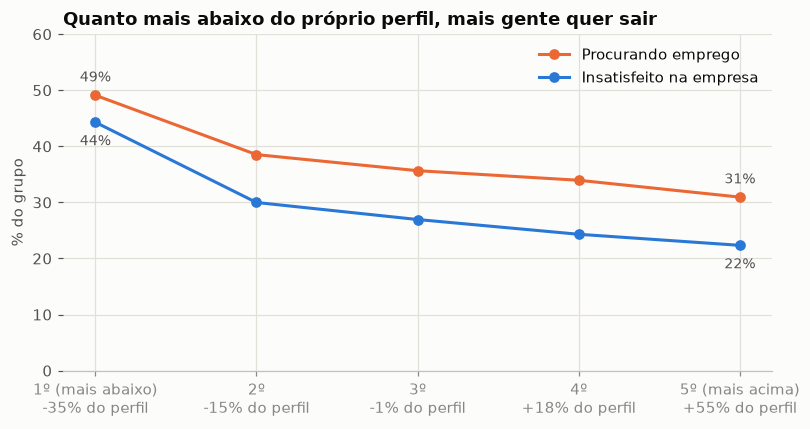

In [2]:
quintos = d.groupby("quinto", observed=True).agg(
    distancia_mediana=("relativo_pct", "median"),
    insatisfeito=("insatisfeito", "mean"),
    procurando_emprego=("buscando", "mean"),
    procurando_so_fora=("so_exterior", "mean"),
    respostas=("relativo", "size"),
)
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(quintos))
for col, cor, nome in [("procurando_emprego", LARANJA, "Procurando emprego"), ("insatisfeito", AZUL, "Insatisfeito na empresa")]:
    ax.plot(x, quintos[col] * 100, marker="o", markersize=6, color=cor, label=nome)
    # rótulo seletivo nas pontas: acima da linha de cima, abaixo da de baixo
    acima = col == "procurando_emprego"
    for i in (0, len(x) - 1):
        ax.annotate(f"{quintos[col].iloc[i]:.0%}", (x[i], quintos[col].iloc[i] * 100), xytext=(0, 9 if acima else -15),
                    textcoords="offset points", ha="center", color=TINTA_2, fontsize=9)
ax.set_xticks(x, [f"{q}\n{m:+.0%} do perfil" for q, m in zip(quintos.index, quintos["distancia_mediana"])])
ax.set_ylim(0, 60)
ax.set_ylabel("% do grupo")
ax.set_title("Quanto mais abaixo do próprio perfil, mais gente quer sair")
ax.legend(loc="upper right")
plt.tight_layout()
quintos.assign(**{c: (quintos[c] * 100).round(1) for c in ["distancia_mediana", "insatisfeito", "procurando_emprego", "procurando_so_fora"]})

No quinto que ganha mais abaixo do próprio perfil (mediana de −35%), **44%
estão insatisfeitos e 49% procuram emprego**. No quinto mais acima (mediana
de +55%), 22% e 31%. A relação é contínua, sem degrau: cada grupo para cima
tem menos insatisfação que o anterior.

Uma exceção instrutiva: **procurar emprego só fora do Brasil cresce com o
salário relativo** (de 7,9% para 10,5%). Quem já ganha bem para o perfil olha
para o exterior; quem ganha mal procura em qualquer lugar.

## Quanto pesa cada 10% abaixo do perfil

Regressão logística, com nível, cargo, ano e modelo de trabalho como
controles; o número é o efeito marginal médio em pontos percentuais.

In [3]:
d["dez_pct_abaixo"] = -d["relativo"] / np.log(1.1)


def efeito_marginal(y, dados, controles="C(nivel_comparavel) + C(ano_c) + C(familia) + C(modelo)"):
    m = smf.logit(f"{y} ~ dez_pct_abaixo + {controles}", sem_categorias_vazias(dados.dropna(subset=[y]))).fit(disp=0)
    r = m.get_margeff().summary_frame().loc["dez_pct_abaixo"]
    return {"p.p. por 10% abaixo": r["dy/dx"] * 100, "IC baixo": r["Conf. Int. Low"] * 100,
            "IC alto": r["Cont. Int. Hi."] * 100, "taxa média (%)": dados[y].mean() * 100, "respostas": int(m.nobs)}


def tabela_marginal(linhas):
    t = pd.DataFrame(linhas).T
    return t.assign(respostas=t["respostas"].astype(int), **{c: t[c].astype(float).round(2) for c in t.columns if c != "respostas"})


insatisfeitos = d[d["insatisfeito"] == 1].dropna(subset=["motivo_salario"]).copy()
insatisfeitos["cita_salario"] = insatisfeitos["motivo_salario"].astype(float)
tabela_marginal({
    "insatisfeito na empresa": efeito_marginal("insatisfeito", d),
    "procurando emprego": efeito_marginal("buscando", d),
    "cita o salário (entre insatisfeitos)": efeito_marginal("cita_salario", insatisfeitos,
                                                            "C(nivel_comparavel) + C(ano_c) + C(familia)"),
})

,p.p. por 10% abaixo,IC baixo,IC alto,taxa média (%),respostas
insatisfeito na empresa,1.93,1.75,2.11,29.58,14639
procurando emprego,1.65,1.45,1.85,37.64,14640
cita o salário (entre insatisfeitos),4.33,4.00,4.65,42.04,4317


**Cada 10% abaixo do próprio perfil soma 1,9 ponto percentual de
insatisfação e 1,65 ponto de procura por emprego**, sobre taxas médias de
30% e 38%. Entre os insatisfeitos, cada 10% abaixo soma 4,3 pontos na chance
de o salário aparecer como motivo.

## Percepção e realidade

Quem diz que o salário é motivo de insatisfação ganha, de fato, abaixo do
próprio perfil?

,distancia_mediana,abaixo_do_perfil,respostas
motivo_salario,,,
não cita,0.7,48.7,2502
cita o salário,-21.3,76.3,1815


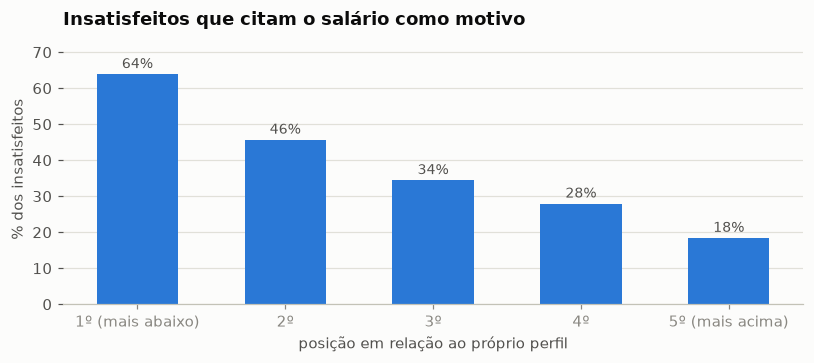

In [4]:
cita = insatisfeitos.groupby("motivo_salario")["relativo_pct"].agg(
    distancia_mediana="median", abaixo_do_perfil=lambda s: (s < 0).mean(), respostas="size")
cita.index = cita.index.map({True: "cita o salário", False: "não cita"})
display(cita.assign(distancia_mediana=(cita["distancia_mediana"] * 100).round(1),
                    abaixo_do_perfil=(cita["abaixo_do_perfil"] * 100).round(1)))

por_quinto = insatisfeitos.groupby("quinto", observed=True)["cita_salario"].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(np.arange(len(por_quinto)), por_quinto * 100, width=0.55, color=AZUL)
for i, v in enumerate(por_quinto):
    ax.annotate(f"{v:.0%}", (i, v * 100), xytext=(0, 4), textcoords="offset points", ha="center", color=TINTA_2, fontsize=9)
ax.set_xticks(np.arange(len(por_quinto)), por_quinto.index)
ax.set_ylim(0, 75)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% dos insatisfeitos")
ax.set_xlabel("posição em relação ao próprio perfil")
ax.set_title("Insatisfeitos que citam o salário como motivo")
plt.tight_layout()

**A percepção bate com a faixa declarada.** Quem cita o salário ganha, na
mediana, 21% abaixo do próprio perfil — e 76% dessas pessoas estão mesmo
abaixo dele. Quem não cita está, na mediana, no próprio perfil. No quinto
mais abaixo, 64% dos insatisfeitos citam o salário; no mais acima, 18%.

Um cuidado: a parcela de insatisfeitos que cita o salário subiu de 39,2%
(2021–2023) para 45,4% (2024–2025), justamente quando o texto da opção
mudou de "Salário atual não corresponde ao mercado" para
"Remuneração/Salário". Não dá para separar o que é mudança de opinião do que
é mudança de redação.

In [5]:
d.groupby("ano")[["insatisfeito", "buscando"]].mean().mul(100).round(1)

,insatisfeito,buscando
ano,,
2021,27.5,37.8
2022,26.3,38.0
2023,28.9,39.1
2024,32.5,36.3
2025,31.6,36.9


Ao longo dos anos, **a insatisfação subiu de 27,5% (2021) para 31,6%
(2025)**, com pico de 32,5% em 2024, enquanto a procura por emprego ficou
estável, entre 36% e 39%. É coerente com o caderno 03 — salário real do
mesmo perfil em queda —, mas a pesquisa não permite afirmar que uma coisa
causa a outra.

## O que isso permite dizer

- **Permite:** entre quem responde, estar abaixo do próprio perfil anda junto
  com insatisfação, intenção de sair e queixa salarial, em todos os níveis de
  distância — e quem reclama do salário, em geral, tem razão.
- **Não permite:** dizer que alguém saiu. "Pretende mudar nos próximos 6
  meses" é intenção declarada; a pesquisa não acompanha as pessoas.
- **O perfil é o que a pesquisa mede.** Duas pessoas iguais nas variáveis do
  modelo podem diferir no que não está nele (empresa, habilidade, área de
  negócio); parte do "abaixo do perfil" é isso.